# Lab 06: Text Classification - Naive Bayes & Logistic Regression
**Course:** AIC365 - Natural Language Processing

**Name:** Urva  
**Roll No:** FA23-BAI-051

# Stage a1 (apply): Lab Activities

### Setup
Install the libraries (only needed once) and load the dataset.

In [1]:
# !pip install pandas scikit-learn
import pandas as pd

df = pd.read_csv('movie_reviews.csv')
print(df.shape)
df.head()

(200, 2)


,text,label
0,The movie was amazing and the acting was brill...,positive
1,"I loved the story, it was touching and beautiful.",positive
2,"What a fantastic film, the music was the best ...",positive
3,The plot was gripping and the ending was perfect.,positive
4,"Great direction and a wonderful cast, highly r...",positive


## Activity 1
Using the provided movie review dataset, build a Bag-of-Words representation with CountVectorizer. Inspect the resulting vocabulary size and print a portion of the sparse document-term matrix in a readable form.

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

# Build Bag-of-Words representation
vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(df['text'])

# Inspect vocabulary
print("Vocabulary size:", len(vectorizer.vocabulary_))

# Print a small portion of the sparse matrix (first 5 documents, first 10 features)
print("\nSparse matrix portion (first 5 docs, first 10 features):")
print(vectorizer.get_feature_names_out()[:10])
print(X_bow[:5, :10].toarray())

Vocabulary size: 155

Sparse matrix portion (first 5 docs, first 10 features):
['acting' 'actors' 'again' 'all' 'almost' 'amazing' 'an' 'and' 'annoying'
 'asleep']
[[1 0 0 0 0 1 0 1 0 0]
 [0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 1 0 0]]


## Activity 2
On the same dataset, build a TF-IDF representation using TfidfVectorizer. Pick two words that appear frequently across many reviews and compare their raw count weight against their TF-IDF weight. Explain in one line why the TF-IDF weight is lower.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Build TF-IDF representation
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df['text'])
vocab = tfidf_vectorizer.vocabulary_

# Pick two common words and a specific document (document index 1)
word1, word2 = 'the', 'was'
idx1, idx2 = vocab.get(word1), vocab.get(word2)

print(f"Document 1: '{df['text'][1]}'")
print(f"'{word1}' -> Raw count: {X_bow[1, idx1]}, TF-IDF: {X_tfidf[1, idx1]:.4f}")
print(f"'{word2}' -> Raw count: {X_bow[1, idx2]}, TF-IDF: {X_tfidf[1, idx2]:.4f}")

print("\nExplanation: The TF-IDF weight is lower relative to its raw frequency because "
      "frequent words appearing across many documents receive a strong Inverse "
      "Document Frequency (IDF) penalty.")

Document 1: 'I loved the story, it was touching and beautiful.'
'the' -> Raw count: 1, TF-IDF: 0.1457
'was' -> Raw count: 1, TF-IDF: 0.1457

Explanation: The TF-IDF weight is lower relative to its raw frequency because frequent words appearing across many documents receive a strong Inverse Document Frequency (IDF) penalty.


**Explanation:** The TF-IDF weight is lower because words like "the" and "was" appear in almost every review, so their IDF value is very small and it pulls down their weight.

## Activity 3
Split the dataset into train and test sets. Train a Multinomial Naive Bayes classifier and a Logistic Regression classifier on the TF-IDF features. Generate predictions for the test set with both models.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Split features and labels (using TF-IDF features from Activity 2)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, df['label'], test_size=0.2, random_state=42
)

# Train and predict with Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

# Train and predict with Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

## Activity 4
Evaluate both trained models from Activity 3 on the test set using accuracy, precision, recall, and F1-score. Generate and display the confusion matrix for each model.

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_and_print(model_name, y_true, y_pred):
    # Calculate metrics treating 'positive' as the target class
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label='positive')
    rec = recall_score(y_true, y_pred, pos_label='positive')
    f1 = f1_score(y_true, y_pred, pos_label='positive')
    cm = confusion_matrix(y_true, y_pred, labels=['negative', 'positive'])

    print(f"--- {model_name} ---")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"Confusion Matrix (Neg, Pos):\n{cm}\n")

evaluate_and_print("Naive Bayes", y_test, nb_preds)
evaluate_and_print("Logistic Regression", y_test, lr_preds)

--- Naive Bayes ---
Accuracy: 0.9750
Precision: 1.0000
Recall: 0.9600
F1-Score: 0.9796
Confusion Matrix (Neg, Pos):
[[15  0]
 [ 1 24]]

--- Logistic Regression ---
Accuracy: 0.9750
Precision: 1.0000
Recall: 0.9600
F1-Score: 0.9796
Confusion Matrix (Neg, Pos):
[[15  0]
 [ 1 24]]



**Observation:** Both models gave the same results on this test set: 97.5% accuracy, precision of 1.0, recall of 0.96 and F1-score of 0.98. Precision of 1.0 means every review they predicted as positive was actually positive, and the only mistake was one positive review predicted as negative. Since both performed equally, Logistic Regression is chosen for the pipeline in Activity 5 because it also gives reliable probability scores and lets us see which words push a review towards positive or negative.

## Activity 5
Wrap the TF-IDF vectorizer and the better-performing classifier from Activity 4 into a single sklearn Pipeline. Use the pipeline to classify three brand-new review sentences that were not part of the dataset.

In [6]:
from sklearn.pipeline import Pipeline

# Split the raw text data so the pipeline can handle vectorization internally
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42
)

# Bundling the vectorizer and classifier (using Logistic Regression)
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression())
])

# Train the pipeline on raw text
pipeline.fit(X_train_text, y_train_text)

# Read new reviews from the text file
try:
    with open('new_reviews.txt', 'r') as f:
        new_reviews = [line.strip() for line in f if line.strip()]

    # Classify the unseen text
    new_preds = pipeline.predict(new_reviews)

    for review, pred in zip(new_reviews, new_preds):
        print(f"Review: {review}\nPrediction: {pred}\n")
except FileNotFoundError:
    print("File 'new_reviews.txt' not found. Please ensure it exists to run predictions.")

Review: The acting was brilliant and I loved the music.
Prediction: positive

Review: This film was a boring waste of my time.
Prediction: negative

Review: A wonderful story with a perfect ending.
Prediction: positive



**Observation:** The pipeline classified all three new reviews correctly. The first and third reviews use words like "brilliant", "loved", "wonderful" and "perfect" so they were predicted positive, and the second review uses "boring" and "waste" so it was predicted negative. The pipeline applies the same TF-IDF transformation automatically, so we can pass raw text directly to `.predict()`.

# Stage v (verify)
Dataset: `app_reviews.csv` (app store reviews labelled positive / negative)

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

app_df = pd.read_csv('app_reviews.csv')
print(app_df.shape)
app_df.head()

(95, 2)


,text,label
0,"Great app, very easy to use.",positive
1,"Love it, works perfectly every time.",positive
2,Super fast and the design is clean.,positive
3,Best app for tracking my expenses.,positive
4,Really helpful and simple interface.,positive


## Activity 1
Using the provided app review dataset, build a full sklearn Pipeline (TF-IDF + your choice of Naive Bayes or Logistic Regression). Train it, then report accuracy, precision, recall, and F1-score on a held-out test split.

In [8]:
# stratify keeps the same positive/negative ratio in train and test sets
X_train_app, X_test_app, y_train_app, y_test_app = train_test_split(
    app_df['text'], app_df['label'], test_size=0.2, random_state=42, stratify=app_df['label']
)

app_model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression())
])
app_model.fit(X_train_app, y_train_app)
app_preds = app_model.predict(X_test_app)

print("Train size:", len(X_train_app), "| Test size:", len(X_test_app))
print(f"Accuracy: {accuracy_score(y_test_app, app_preds):.4f}\n")

for label in ['negative', 'positive']:
    p = precision_score(y_test_app, app_preds, pos_label=label, zero_division=0)
    r = recall_score(y_test_app, app_preds, pos_label=label, zero_division=0)
    f = f1_score(y_test_app, app_preds, pos_label=label, zero_division=0)
    print(f"Class '{label}' -> Precision: {p:.4f} | Recall: {r:.4f} | F1-Score: {f:.4f}")

Train size: 76 | Test size: 19
Accuracy: 0.7368

Class 'negative' -> Precision: 0.0000 | Recall: 0.0000 | F1-Score: 0.0000
Class 'positive' -> Precision: 0.7368 | Recall: 1.0000 | F1-Score: 0.8485


## Activity 2
On the same app review dataset, plot the confusion matrix for your trained model. In 3-4 sentences, explain what the matrix reveals about which class the model struggles with most.

[[ 0  5]
 [ 0 14]]


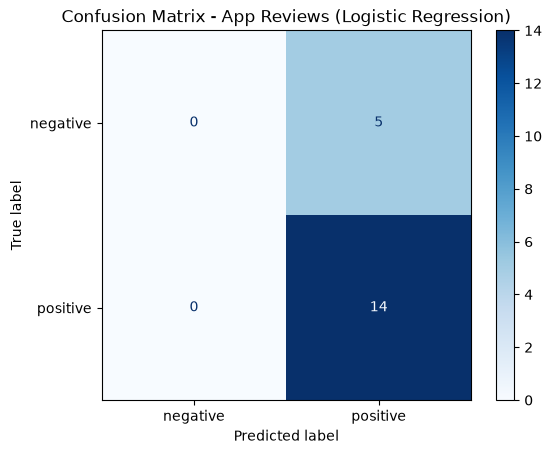

In [9]:
cm = confusion_matrix(y_test_app, app_preds, labels=['negative', 'positive'])
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['negative', 'positive'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - App Reviews (Logistic Regression)')
plt.show()

**Explanation:** The confusion matrix shows that all 14 positive reviews were predicted correctly, but all 5 negative reviews were wrongly predicted as positive. So the model struggles completely with the negative class and never predicts it even once. This happens because the dataset is imbalanced (only 25 of 95 reviews are negative), so the model learns to favour the majority positive class. The accuracy of 73.7% looks okay, but it is misleading because the model is basically just saying "positive" for everything.

## Activity 3
Build a DataFrame of every misclassified example from the test set, with columns text, true_label, predicted_label, and predicted_probability (using `.predict_proba()`). Sort it by predicted_probability in descending order and print the top 5 rows.

In [10]:
probs = app_model.predict_proba(X_test_app)

wrong = []
for text, true, pred, prob in zip(X_test_app, y_test_app, app_preds, probs):
    if true != pred:
        wrong.append({
            'text': text,
            'true_label': true,
            'predicted_label': pred,
            'predicted_probability': round(prob.max(), 4)   # confidence of the predicted class
        })

wrong_df = pd.DataFrame(wrong, columns=['text', 'true_label', 'predicted_label', 'predicted_probability'])
wrong_df = wrong_df.sort_values('predicted_probability', ascending=False)

print("Total misclassified:", len(wrong_df))
wrong_df.head(5)

Total misclassified: 5


,text,true_label,predicted_label,predicted_probability
4,"Horrible experience, the app is broken.",negative,positive,0.7815
2,Payment failed and no refund given.,negative,positive,0.7691
3,"Worst update ever, now it crashes.",negative,positive,0.6999
1,Lost all my data after the update.,negative,positive,0.6692
0,"Not working since yesterday, fix it.",negative,positive,0.6286


**Observation:** All 5 misclassified reviews are negative reviews that the model predicted as positive, with 63% to 78% confidence. Some of them contain very clear negative words like "horrible", "broken" and "worst", but these words appear only a few times in the small training set, so the model did not learn them strongly enough to beat its bias towards the positive class.

## Activity 4
Compute the class distribution using `.value_counts()`. Then retrain the pipeline with class balancing (`class_weight='balanced'`) and print a side-by-side comparison of precision, recall, and F1 for the negative class: original model vs rebalanced model.

In [11]:
print("Class distribution:")
print(app_df['label'].value_counts())

balanced_model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(class_weight='balanced'))
])
balanced_model.fit(X_train_app, y_train_app)
balanced_preds = balanced_model.predict(X_test_app)

def negative_scores(y_true, y_pred):
    return (precision_score(y_true, y_pred, pos_label='negative', zero_division=0),
            recall_score(y_true, y_pred, pos_label='negative', zero_division=0),
            f1_score(y_true, y_pred, pos_label='negative', zero_division=0))

original = negative_scores(y_test_app, app_preds)
balanced = negative_scores(y_test_app, balanced_preds)

print("\nNegative class comparison:")
print(f"{'Metric':<12}| {'Original':<10}| {'Balanced'}")
print("-" * 34)
for name, o, b in zip(['Precision', 'Recall', 'F1-Score'], original, balanced):
    print(f"{name:<12}| {o:<10.4f}| {b:.4f}")

Class distribution:
label
positive    70
negative    25
Name: count, dtype: int64

Negative class comparison:
Metric      | Original  | Balanced
----------------------------------
Precision   | 0.0000    | 1.0000
Recall      | 0.0000    | 0.6000
F1-Score    | 0.0000    | 0.7500


**Observation:** The dataset has 70 positive and 25 negative reviews (about 74% vs 26%), so it is imbalanced. After using `class_weight='balanced'`, the negative-class recall went from 0.00 to 0.60 and the F1-score from 0.00 to 0.75, which means the model now catches 3 out of 5 negative reviews. Precision is 1.00, so every review it flagged as negative was actually negative. This shows that balancing really fixed the problem instead of just looking good on accuracy.

## Activity 5
A small business wants to auto-flag negative app reviews for their support team to respond to first. Using the trained pipeline from Activity 1, run it on new unseen customer feedback, list which ones get flagged as negative, and write a short recommendation on how reliable this auto-flagging is.

In [12]:
feedback = [
    "The app crashed twice while I was paying my bill.",
    "Really love the new design, great work!",
    "I cannot log in since the last update.",
    "Delivery tracking is quick and accurate.",
    "Too many ads, it is getting annoying.",
    "Support team helped me in five minutes, thanks.",
    "My order history disappeared, please fix this.",
    "It is okay but sometimes a bit slow.",
]

feedback_preds = app_model.predict(feedback)
neg_index = list(app_model.classes_).index('negative')
neg_probs = app_model.predict_proba(feedback)[:, neg_index]

print("FLAGGED AS NEGATIVE:")
for text, pred, p in zip(feedback, feedback_preds, neg_probs):
    if pred == 'negative':
        print(f"  [!] {text}  (negative prob = {p:.2f})")

print("\nNOT FLAGGED:")
for text, pred, p in zip(feedback, feedback_preds, neg_probs):
    if pred != 'negative':
        print(f"  {text}  (negative prob = {p:.2f})")

# for comparison: the balanced model from Activity 4
balanced_flags = balanced_model.predict(feedback)
print("\nFLAGGED BY THE BALANCED MODEL (Activity 4):")
for text, pred in zip(feedback, balanced_flags):
    if pred == 'negative':
        print(f"  [!] {text}")

FLAGGED AS NEGATIVE:

NOT FLAGGED:
  The app crashed twice while I was paying my bill.  (negative prob = 0.30)
  Really love the new design, great work!  (negative prob = 0.22)
  I cannot log in since the last update.  (negative prob = 0.26)
  Delivery tracking is quick and accurate.  (negative prob = 0.19)
  Too many ads, it is getting annoying.  (negative prob = 0.39)
  Support team helped me in five minutes, thanks.  (negative prob = 0.28)
  My order history disappeared, please fix this.  (negative prob = 0.28)
  It is okay but sometimes a bit slow.  (negative prob = 0.30)

FLAGGED BY THE BALANCED MODEL (Activity 4):
  [!] Too many ads, it is getting annoying.
  [!] It is okay but sometimes a bit slow.


**Recommendation:** The original model from Activity 1 is not reliable for auto-flagging, because its recall for the negative class is 0. It did not flag any of the 8 snippets, even obvious complaints like the app crashing or not being able to log in. The balanced model is better (precision 1.00, recall 0.60), but on this new feedback it flagged only 2 complaints and still missed the crash, login and lost order history ones. So I would recommend using the balanced model only as a helper to sort reviews, while the support team still checks the unflagged reviews, and collecting more labelled negative reviews to retrain the model before relying on it fully.